In [199]:
# imports
import numpy as np 
import pandas as pd 
import os
import matplotlib.pyplot as pl
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

In [200]:
# Importamos los datos
data = pd.read_csv('../Data/insurance.csv')

# Comprobamos que tenemos acceso al documento visualizando una muestra
data.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [201]:
# Hacemos un estudio de los valores nulos
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [202]:
# Arreglo de los NaN data
# Columna sex
le = LabelEncoder()
le.fit(data.sex.drop_duplicates()) 
data.sex = le.transform(data.sex)
# Columna fumador
le.fit(data.smoker.drop_duplicates()) 
data.smoker = le.transform(data.smoker)
# COlumna region
le.fit(data.region.drop_duplicates()) 
data.region = le.transform(data.region)

In [203]:
data.corr()['charges'].sort_values()

region     -0.006208
sex         0.057292
children    0.067998
bmi         0.198341
age         0.299008
smoker      0.787251
charges     1.000000
Name: charges, dtype: float64

<Axes: >

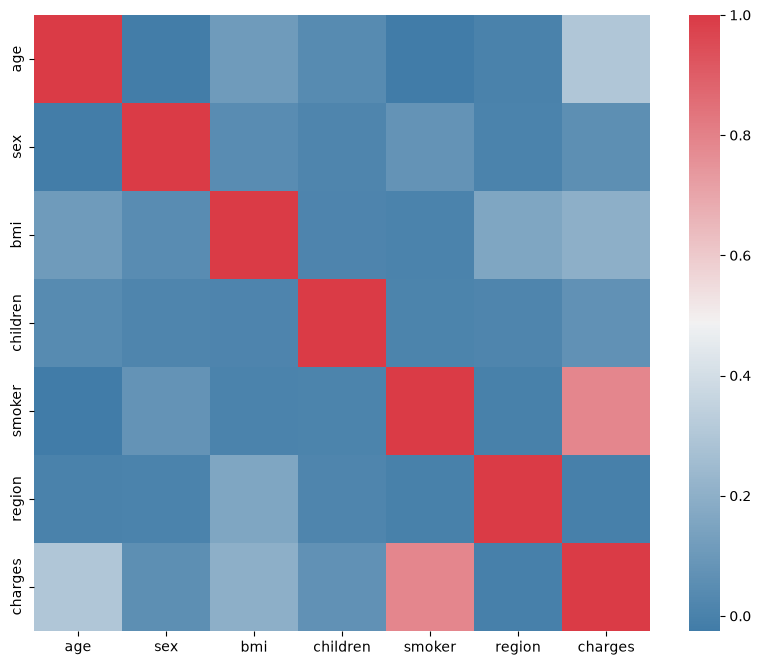

In [204]:
# Con este mapa de calor buscamos ver la relación de ser fumador con el IMC de la persona.
f, ax = pl.subplots(figsize=(10, 8))
corr = data.corr()
sns.heatmap(corr, mask=np.zeros_like(corr, dtype=np.bool), cmap=sns.diverging_palette(240,10,as_cmap=True), square=True, ax=ax)
# Vemos que la relación es fuerte por ser fumador, pero no al contrario de lo que se espera el IMC no hace que esto sea mayor.

In [205]:
# Ahora buscamos comparar la distribución de los costes
from bokeh.io import output_notebook, show
from bokeh.plotting import figure 
output_notebook()
import scipy.special
from bokeh.layouts import gridplot
from bokeh.plotting import figure, show, output_file
p = figure(title="Distribution of charges",tools="save", background_fill_color="#E8DDCB")
hist, edges = np.histogram(data.charges)
p.quad(top=hist, bottom=0, left=edges[:-1], right=edges[1:], fill_color="#036564", line_color="#033649")
p.xaxis.axis_label = 'x'
p.yaxis.axis_label = 'Pr(x)'
show(p)



Loading BokehJS ...

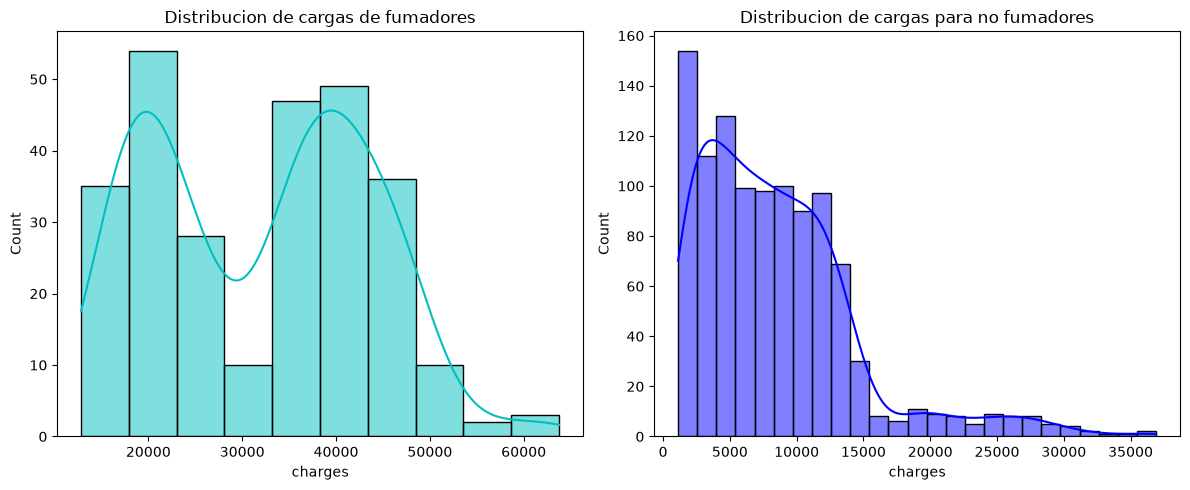

In [206]:
import matplotlib.pyplot as plt
import seaborn as sns

# Creamos la figura y los subplots de forma más limpia con plt.subplots
f, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico para fumadores (smoker == 1)
sns.histplot(data[data.smoker == 1]["charges"], color='c', ax=axes[0], kde=True)
axes[0].set_title('Distribucion de cargas de fumadores')

# Gráfico para no fumadores (smoker == 0)
sns.histplot(data[data.smoker == 0]['charges'], color='b', ax=axes[1], kde=True)
axes[1].set_title('Distribucion de cargas para no fumadores')

plt.tight_layout()
plt.show()

#Los pacientes fumadores gastan más en tratamiento. Parece que el número de pacientes no fumadores es mayor. Hay que revisarlo.

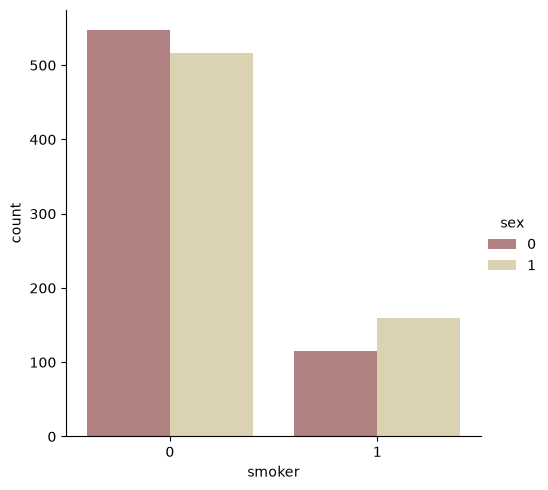

In [207]:
sns.catplot(x="smoker", kind="count",hue = 'sex', palette="pink", data=data)

# Las mujeres están codificadas con el símbolo "1" y los hombres con el "0".
# Por lo tanto, hay más personas no fumadoras.
# También observamos que hay más hombres fumadores que mujeres fumadoras.
# Se puede suponer que el costo total del tratamiento en hombres será mayor que en mujeres, dado el impacto del tabaquismo.

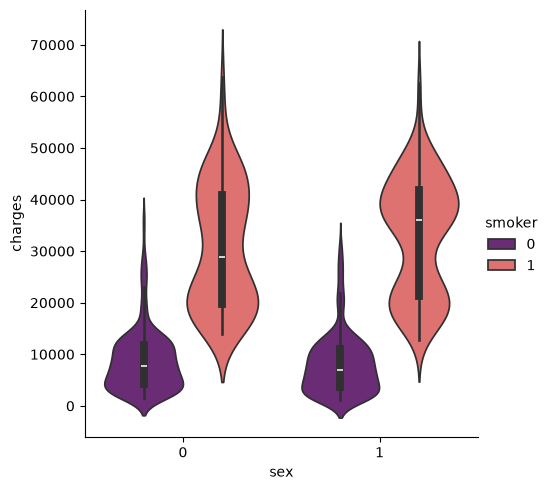

In [208]:
sns.catplot(x="sex", y="charges", hue="smoker", kind="violin", data=data, palette = 'magma')

<Axes: title={'center': 'Box plot cargas a las mujeres'}, xlabel='charges', ylabel='smoker'>

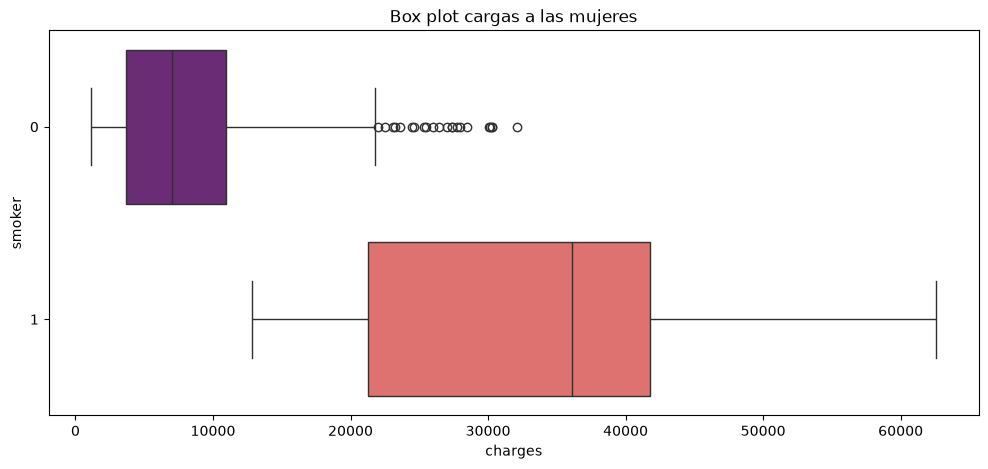

In [209]:
pl.figure(figsize=(12,5))
pl.title("Box plot cargas a las mujeres")
sns.boxplot(y="smoker", x="charges", data =  data[(data.sex == 1)] , orient="h", palette = 'magma')

<Axes: title={'center': 'Box plot cargas a los hombres'}, xlabel='charges', ylabel='smoker'>

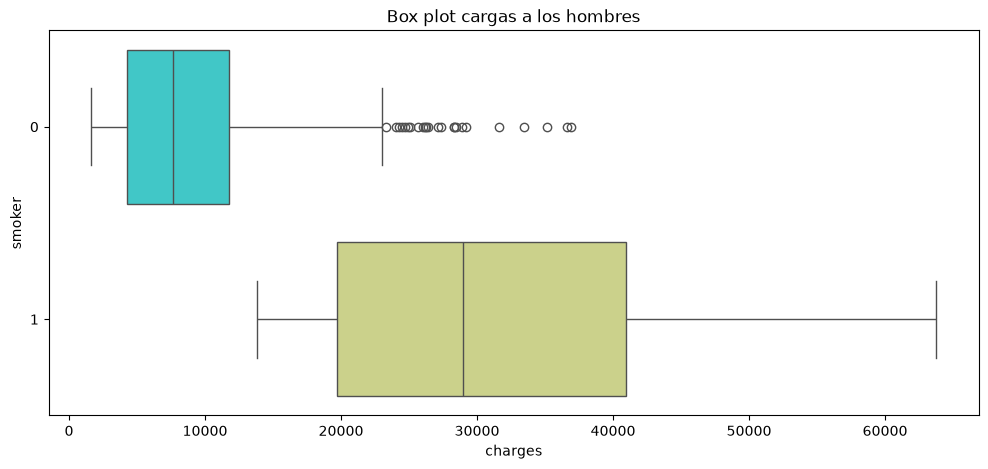

In [210]:
pl.figure(figsize=(12,5))
pl.title("Box plot cargas a los hombres")
sns.boxplot(y="smoker", x="charges", data =  data[(data.sex == 0)] , orient="h", palette = 'rainbow')

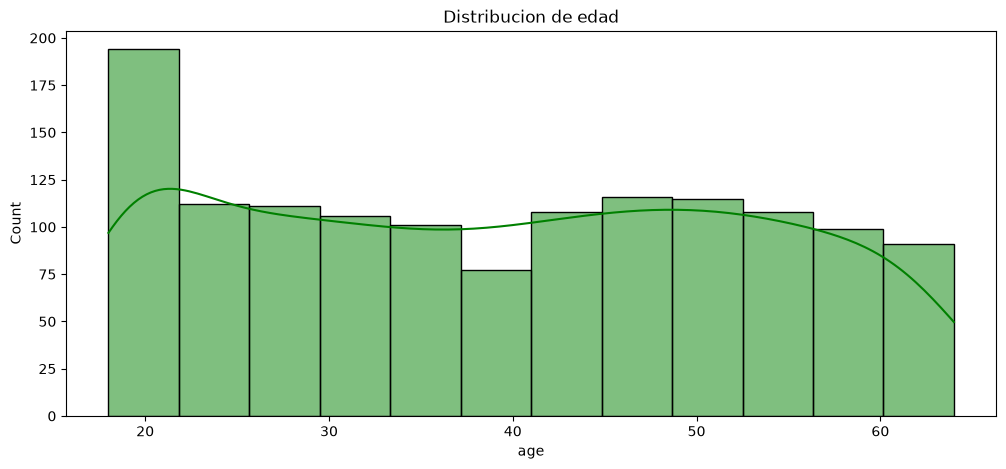

In [211]:
# Si miramos la edad de los pacientes. Primero, veamos cómo la edad afecta el costo del tratamiento y también qué grupo de edad es más frecuente en nuestro conjunto de datos.

pl.figure(figsize=(12,5))
pl.title("Distribucion de edad")
ax = sns.histplot(data["age"], color='g', kde=True)

Text(0.5, 1.0, 'Número de fumadores y no fumadores en los pacientes de 18 años')

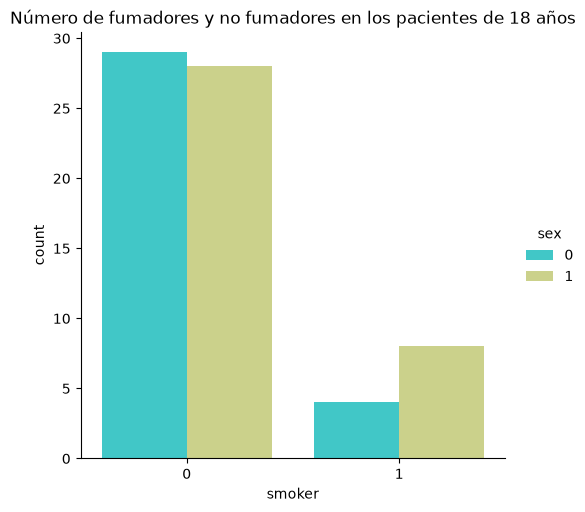

In [212]:
# La edad mínima de los pacientes es 18 y la máxima es 64 años.
# Queremos saber si hay fumadores entre los pacientes de 18 años.

sns.catplot(x="smoker", kind="count",hue = 'sex', palette="rainbow", data=data[(data.age == 18)])
pl.title("Número de fumadores y no fumadores en los pacientes de 18 años")

<Axes: title={'center': 'Box plot para fumadores de 18 años'}, xlabel='charges', ylabel='smoker'>

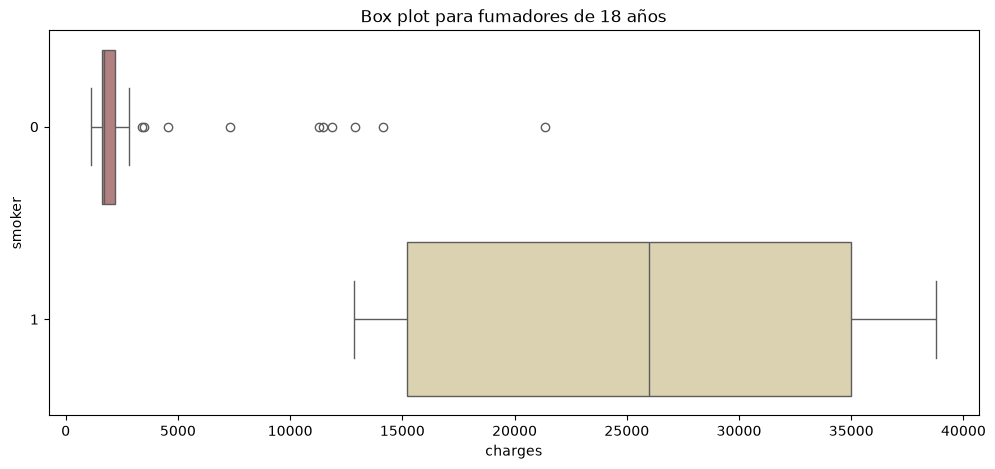

In [213]:
# ¿Influye el tabaquismo en el costo del tratamiento a esta edad?
pl.figure(figsize=(12,5))
pl.title("Box plot para fumadores de 18 años")
sns.boxplot(y="smoker", x="charges", data = data[(data.age == 18)] , orient="h", palette = 'pink')

In [214]:
# Incluso con 18 años, los fumadores gastan mucho más en tratamiento que los no fumadores.
# Entre los no fumadores, hay ciertos «outliers».
# Esto puede ser enfermedades graves o accidentes.
# Veamos ahora cómo depende el coste del tratamiento de la edad de los pacientes, tanto fumadores como no fumadores.

Text(0.5, 1.0, 'Distribucion de cargas y edad para no fumadores')

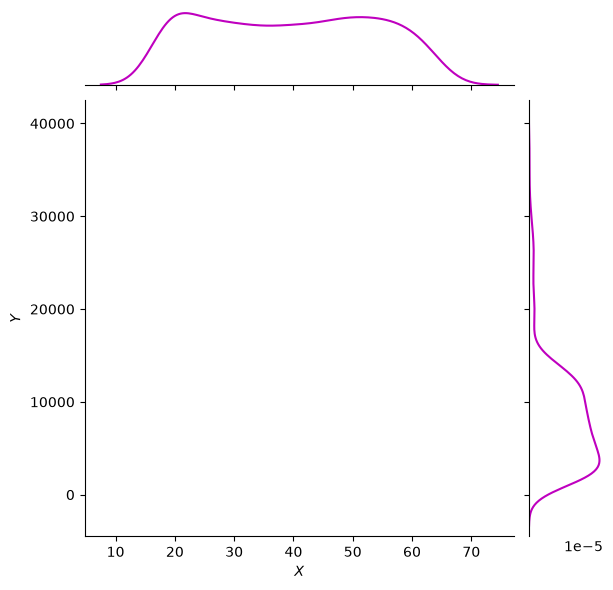

In [215]:
g = sns.jointplot(x="age", y="charges", data = data[(data.smoker == 0)],kind="kde", color="m")
g.plot_joint(pl.scatter, c="w", s=30, linewidth=1, marker="+")
g.ax_joint.collections[0].set_alpha(0)
g.set_axis_labels("$X$", "$Y$")
ax.set_title('Distribucion de cargas y edad para no fumadores')
#Está saliendo mál la gráfica!!!

Text(0.5, 1.0, 'Distribucion de cargas y edad para fumadores')

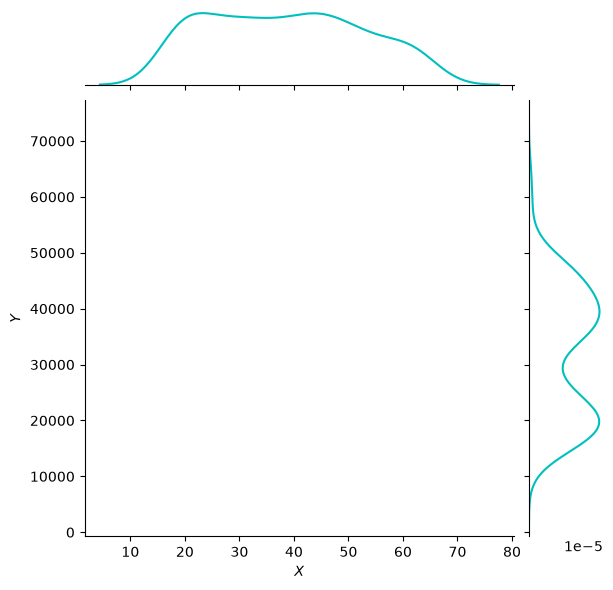

In [216]:
g = sns.jointplot(x="age", y="charges", data = data[(data.smoker == 1)],kind="kde", color="c")
g.plot_joint(pl.scatter, c="w", s=30, linewidth=1, marker="+")
g.ax_joint.collections[0].set_alpha(0)
g.set_axis_labels("$X$", "$Y$")
ax.set_title('Distribucion de cargas y edad para fumadores')

#Revisar!!! Faltan datos

In [217]:
# No fumadores
p = figure(width=500, height=450)
p.circle(x=data[(data.smoker == 0)].age,y=data[(data.smoker == 0)].charges, size=7, line_color="navy", fill_color="pink", fill_alpha=0.9)

show(p)

In [218]:
# Fumadores
p = figure(width=500, height=450)
p.circle(x=data[(data.smoker == 1)].age,y=data[(data.smoker == 1)].charges, size=7, line_color="navy", fill_color="red", fill_alpha=0.9)
show(p)

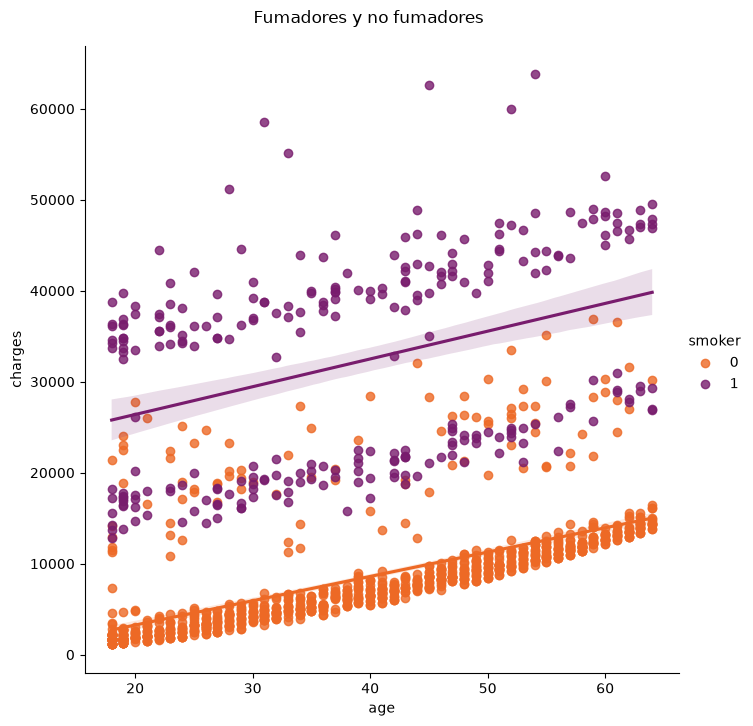

In [219]:
g = sns.lmplot(x="age", y="charges", hue="smoker", data=data, palette='inferno_r', height=7)
g.figure.suptitle('Fumadores y no fumadores', y=1.03)
plt.show()

In [220]:
# En el caso de los no fumadores, el costo del tratamiento aumenta con la edad.
# Entre los fumadores, no observamos esa misma relación. 
# Para evaluar con mayor rigor el impacto del tabaquismo en el costo del tratamiento, sería ideal contar con un conjunto de datos que incluya un mayor número de registros y variables.
# Prestemos atención al IMC (índice de masa corporal). Este indicador no influye en el costo del tratamiento de los pacientes. ¿Hacer dieta para nada?

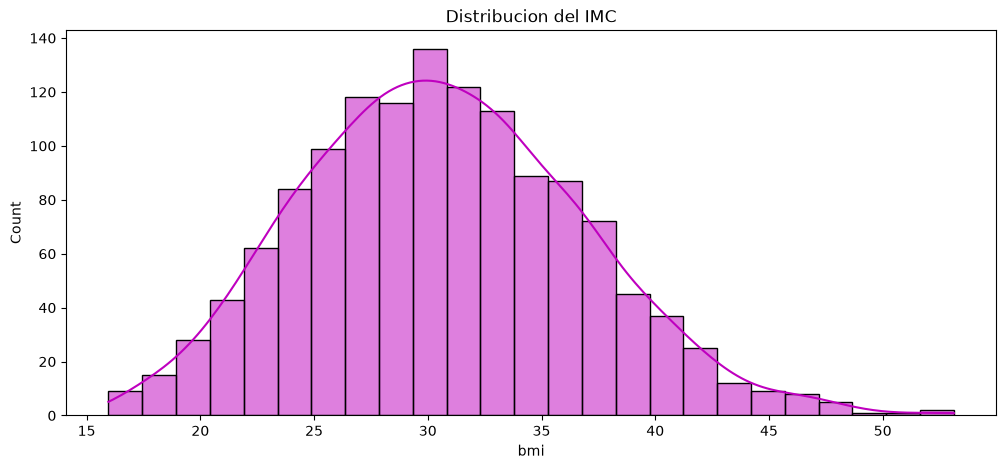

In [221]:
pl.figure(figsize=(12, 5))
pl.title("Distribucion del IMC")
ax = sns.histplot(data["bmi"], color='m', kde=True)
plt.show()

In [222]:
# El IMC promedio de los pacientes es 30.
# La obesidad comienza con un valor de 30.
# Analizamos la distribución de los costos en pacientes con un IMC superior a 30 y en aquellos con un IMC inferior a 30.

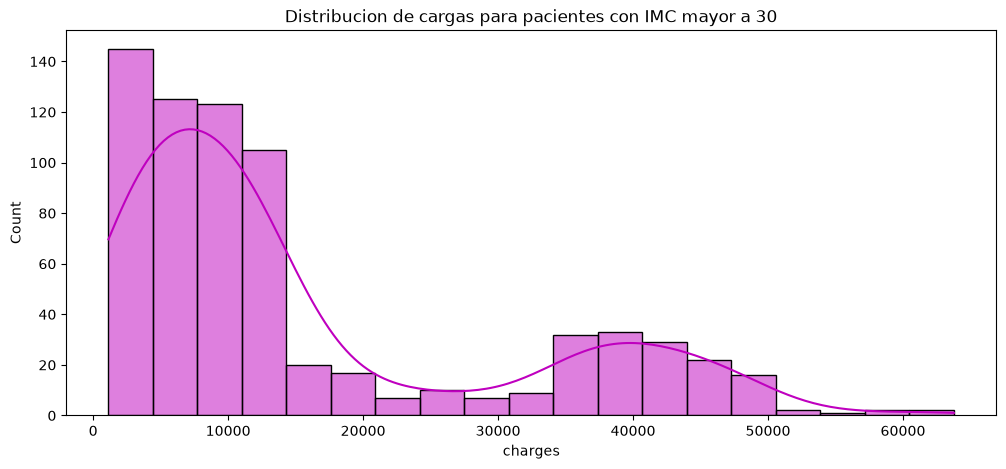

In [223]:
pl.figure(figsize=(12,5))
pl.title("Distribucion de cargas para pacientes con IMC mayor a 30")
ax = sns.histplot(data[(data.bmi >= 30)]['charges'], color = 'm', kde=True)

plt.show()

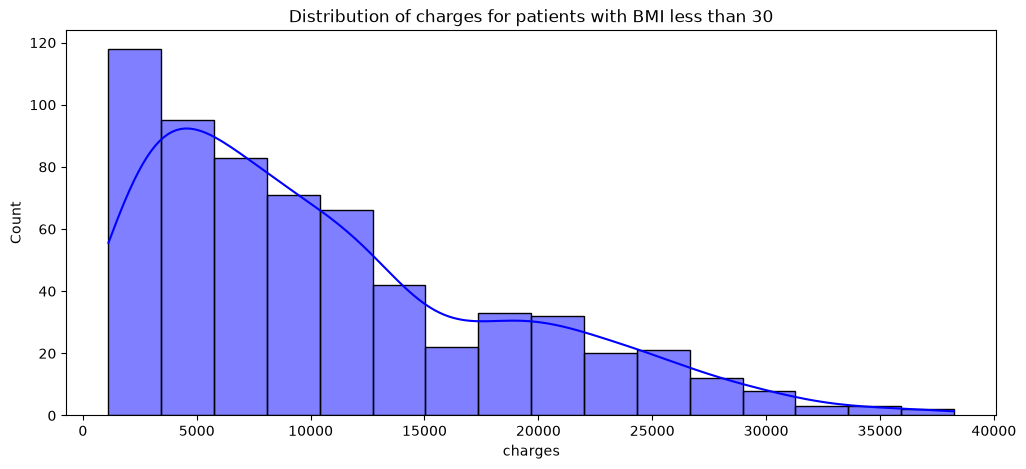

In [224]:
pl.figure(figsize=(12,5))
pl.title("Distribution of charges for patients with BMI less than 30")
ax = sns.histplot(data[(data.bmi < 30)]['charges'], color = 'b', kde=True)

plt.show()

In [225]:
# ¡Los pacientes con un IMC superior a 30 gastan más en su tratamiento!

Text(0.5, 1.0, 'Distribution of bmi and charges')

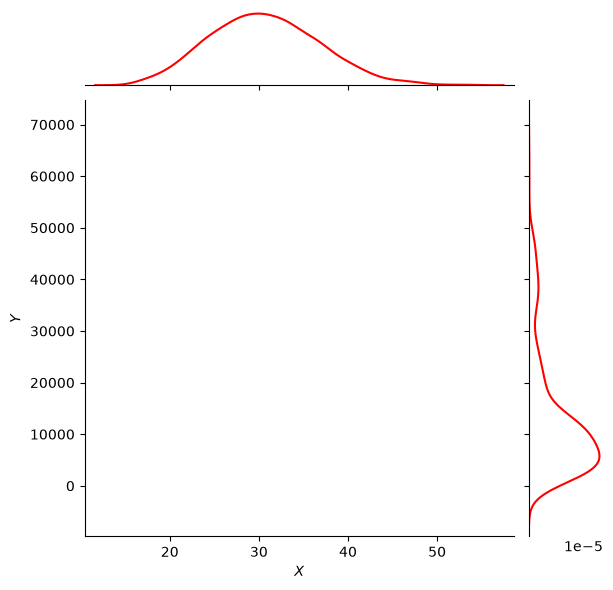

In [226]:
g = sns.jointplot(x="bmi", y="charges", data = data,kind="kde", color="r")
g.plot_joint(pl.scatter, c="w", s=30, linewidth=1, marker="+")
g.ax_joint.collections[0].set_alpha(0)
g.set_axis_labels("$X$", "$Y$")
ax.set_title('Distribution of bmi and charges')
#Revisar, faltan datos

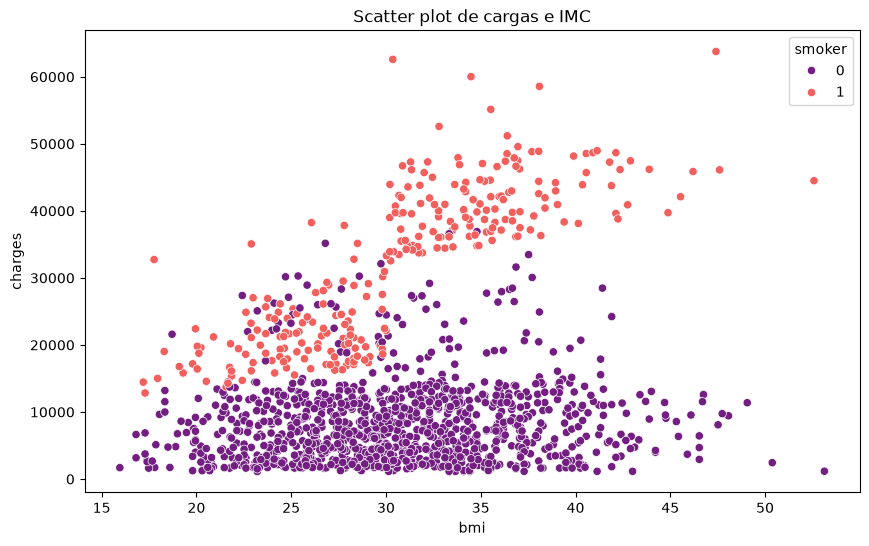

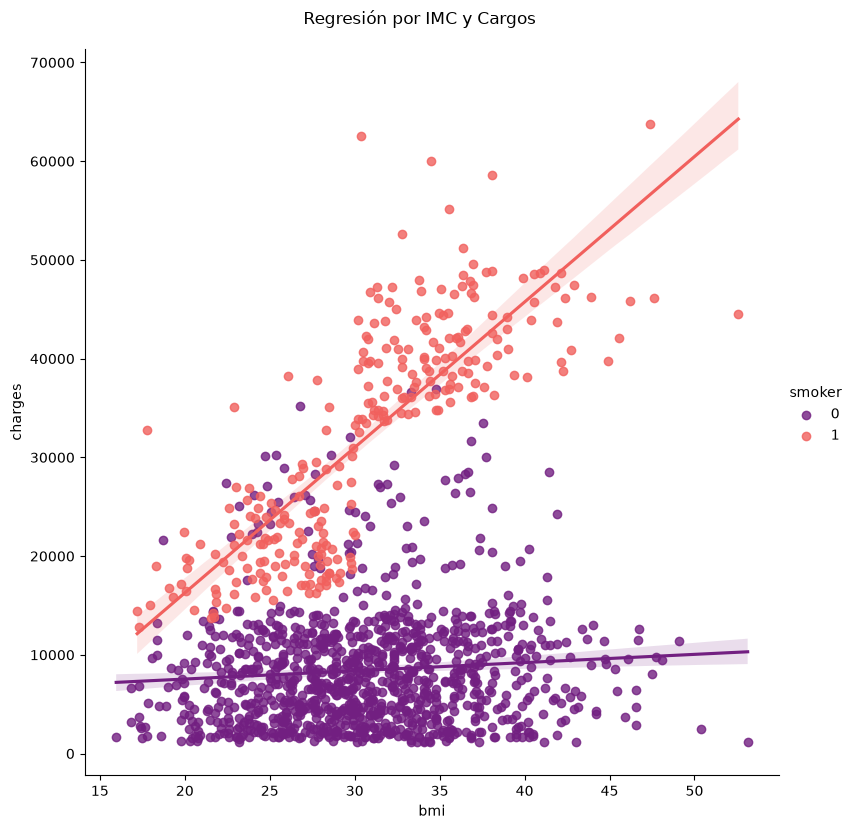

In [227]:
pl.figure(figsize=(10,6))
ax = sns.scatterplot(x='bmi',y='charges',data=data,palette='magma',hue='smoker')
ax.set_title('Scatter plot de cargas e IMC')

pl.show()

g = sns.lmplot(x="bmi", y="charges", hue="smoker", data=data, palette='magma', height=8)
g.figure.suptitle('Regresión por IMC y Cargos', y=1.03)

pl.show()

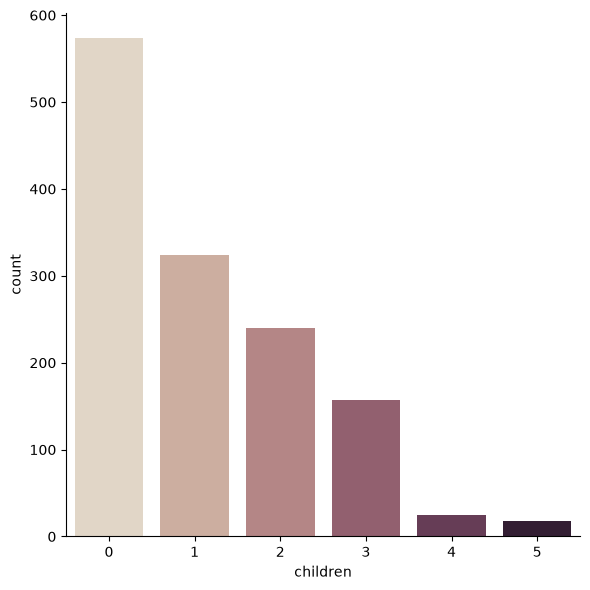

In [228]:
# Miramos cuantos hijos tienen los pacientes.
sns.catplot(x="children", kind="count", palette="ch:.25", data=data, height=6)

plt.show()

In [229]:
# La mayoría de los pacientes no tienen hijos.
# Las personas que tienen hijos fuman?.

Text(0.5, 1.0, 'Fumadores y no fumadores que tienen hijos')

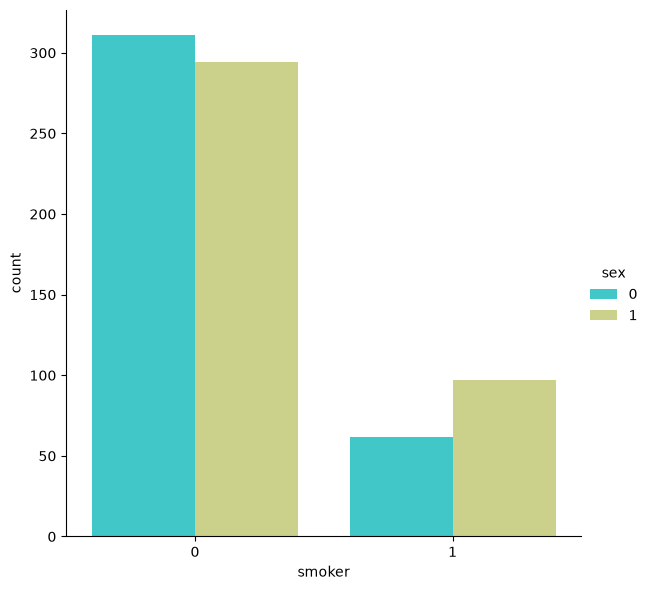

In [230]:
sns.catplot(x="smoker", kind="count", palette="rainbow",hue = "sex", data=data[(data.children > 0)], height = 6)
ax.set_title('Fumadores y no fumadores que tienen hijos')

In [231]:
# Hay más padres que no fuman que fumadores.
# Ahora vemos la regresión lineal.

In [232]:
x = data.drop(['charges'], axis = 1)
y = data.charges

x_train,x_test,y_train,y_test = train_test_split(x,y, random_state = 0)
lr = LinearRegression().fit(x_train,y_train)

y_train_pred = lr.predict(x_train)
y_test_pred = lr.predict(x_test)

print(lr.score(x_test,y_test))

0.7962732059725786


In [233]:
# Ahora, vemos términos polinómicos.

In [234]:
X = data.drop(['charges','region'], axis = 1)
Y = data.charges

quad = PolynomialFeatures (degree = 2)
x_quad = quad.fit_transform(X)

X_train,X_test,Y_train,Y_test = train_test_split(x_quad,Y, random_state = 0)

plr = LinearRegression().fit(X_train,Y_train)

Y_train_pred = plr.predict(X_train)
Y_test_pred = plr.predict(X_test)

print(plr.score(X_test,Y_test))

0.8849197344147236


In [235]:
# El modelo predice correctamente el costo del tratamiento de los pacientes.
# Ahora probamos con `RandomForestRegressor`.

In [237]:
forest = RandomForestRegressor(n_estimators = 100, criterion = 'squared_error', random_state = 1, n_jobs = -1)
forest.fit(x_train,y_train)
forest_train_pred = forest.predict(x_train)
forest_test_pred = forest.predict(x_test)

print('MSE train data: %.3f, MSE test data: %.3f' % (
mean_squared_error(y_train,forest_train_pred),
mean_squared_error(y_test,forest_test_pred)))
print('R2 train data: %.3f, R2 test data: %.3f' % (
r2_score(y_train,forest_train_pred),
r2_score(y_test,forest_test_pred)))

MSE train data: 3735309.198, MSE test data: 19955154.565
R2 train data: 0.974, R2 test data: 0.873


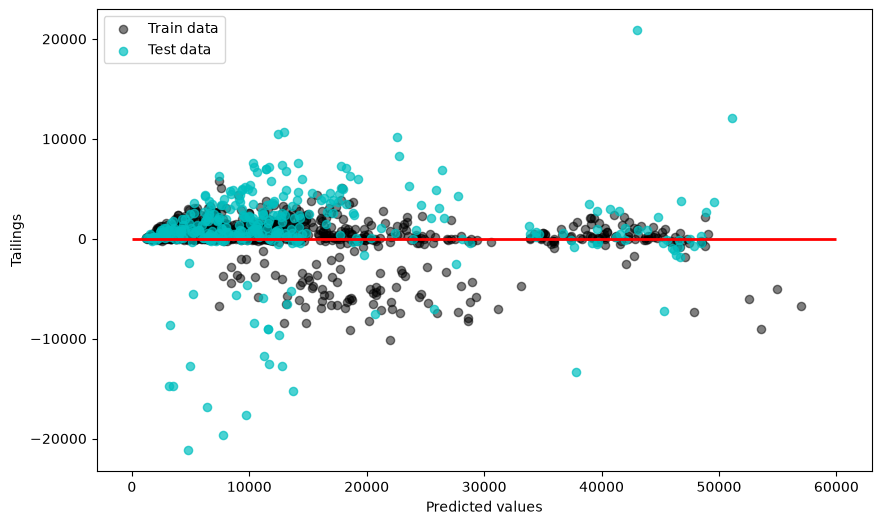

In [238]:
pl.figure(figsize=(10,6))

pl.scatter(forest_train_pred,forest_train_pred - y_train,
          c = 'black', marker = 'o', s = 35, alpha = 0.5,
          label = 'Train data')
pl.scatter(forest_test_pred,forest_test_pred - y_test,
          c = 'c', marker = 'o', s = 35, alpha = 0.7,
          label = 'Test data')
pl.xlabel('Predicted values')
pl.ylabel('Tailings')
pl.legend(loc = 'upper left')
pl.hlines(y = 0, xmin = 0, xmax = 60000, lw = 2, color = 'red')
pl.show()

In [239]:
# Buen resultado. Observamos un overfitting considerable del algoritmo con respecto a los datos de entrenamiento.